# Core

In [1]:
# ============================================================
# Imports and output paths
# ============================================================

import sys
import subprocess
import importlib.util
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import least_squares, curve_fit
from scipy.special import expit

OUTDIR = Path('.')
FIG_CHAP1 = OUTDIR
FIGS = OUTDIR
TABLES = OUTDIR
DATA = OUTDIR

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "figure.titlesize": 14,
    "savefig.dpi": 300,
})

rng_global = np.random.default_rng(123)


In [2]:
# ============================================================
# Core parameter dictionaries
# ============================================================

AP_BASE = dict(
    Cm=1.0,
    V_Na=45.0,
    V_K=-82.0,
    V0=-70.0,
    V_th=-60.0,
    V_max=-18.0,
    G_Na_min=0.01600,
    G_K_min=9.5 * 0.01600,
    C_Na=0.00550,
    C_K=0.12500,
    tau_m=0.19903,
    tau_h=2.75768,
    tau_K=1.3,
    spike_threshold=0.0,
    # Reference notebook convention used by the published computations:
    # h(V)=max(V_max - V, 0).  Keep this fixed for Figures 1--12.
    use_manuscript_h_gate=False,
)

SIM = dict(
    T_max=100.0,
    dt=0.001,
    count_start_ms=0.0,
    I_values=[1, 2, 4, 8, 16, 32],
)

CFG_GATE = dict(
    Iext_post=0.0,
    tau_syn_E=2.0,
    tau_syn_I=2.0,
    W_syn_E=1.3e-5,
    W_syn_I=8.0e-5,
    V_syn_E=0.0,
    V_syn_I=-70.0,
)

CFG_SUBTRACTION = dict(
    Iext_post=2.0,
    tau_syn_E=2.0,
    tau_syn_I=2.0,
    W_syn_E=0.85e-5,
    W_syn_I=6.0e-5,
    V_syn_E=0.0,
    V_syn_I=-70.0,
)

F0 = 100.0


In [3]:
# ============================================================
# Delay-based AP model and synaptic simulators
# ============================================================

def make_time(sim):
    dt = float(sim["dt"])
    T_max = float(sim["T_max"])
    t = np.arange(0.0, T_max + dt, dt)
    return t, len(t), dt, T_max


def delayed_value(V_array, i, delay_ms, dt, V0):
    k = int(round(delay_ms / dt))
    j = i - k
    return V0 if j < 0 else V_array[j]


def m_gate(V, ap):
    return max(V - ap["V_th"], 0.0)


def n_gate(V, ap):
    return max(V - ap["V_th"], 0.0)


def h_gate(V, ap):
    if ap.get("use_manuscript_h_gate", True):
        return max(ap["V_max"] - max(V, ap["V_th"]), 0.0)
    return max(ap["V_max"] - V, 0.0)


def ionic_current(V_now, Vm, Vh, Vk, ap):
    m = m_gate(Vm, ap)
    h = h_gate(Vh, ap)
    n = n_gate(Vk, ap)
    GNa = ap["G_Na_min"] + ap["C_Na"] * m * h
    GK = ap["G_K_min"] + ap["C_K"] * n
    I_ion = GK * (V_now - ap["V_K"]) + GNa * (V_now - ap["V_Na"])
    return I_ion, m, h, n, GNa, GK


def spike_frequency(V, sim, threshold=None, count_start_ms=None):
    dt = float(sim["dt"])
    T_max = float(sim["T_max"])
    if threshold is None:
        threshold = AP_BASE["spike_threshold"]
    if count_start_ms is None:
        count_start_ms = float(sim.get("count_start_ms", 0.0))
    i0 = int(round(count_start_ms / dt))
    i0 = max(0, min(i0, len(V) - 2))
    Vc = V[i0:]
    crossings = np.sum((Vc[1:] >= threshold) & (Vc[:-1] < threshold))
    T_count = max((T_max - count_start_ms) / 1000.0, dt / 1000.0)
    return crossings / T_count


def simulate_single_neuron(Iext, ap=None, sim=None):
    ap = AP_BASE.copy() if ap is None else ap.copy()
    sim = SIM.copy() if sim is None else sim.copy()
    t, N, dt, T_max = make_time(sim)
    V = np.full(N, ap["V0"], dtype=float)
    for i in range(N - 1):
        Vm = delayed_value(V, i, ap["tau_m"], dt, ap["V0"])
        Vh = delayed_value(V, i, ap["tau_h"], dt, ap["V0"])
        Vk = delayed_value(V, i, ap["tau_K"], dt, ap["V0"])
        I_ion, *_ = ionic_current(V[i], Vm, Vh, Vk, ap)
        V[i + 1] = V[i] + dt * (-(I_ion - Iext) / ap["Cm"])
    f = spike_frequency(V, sim, threshold=ap["spike_threshold"])
    return dict(t=t, V=V, f=f)


def simulate_two_neuron(Iext_pre, Iext_post, tau_syn, W_syn, V_syn, ap=None, sim=None):
    ap = AP_BASE.copy() if ap is None else ap.copy()
    sim = SIM.copy() if sim is None else sim.copy()
    t, N, dt, T_max = make_time(sim)
    V_pre = np.full(N, ap["V0"], dtype=float)
    V_post = np.full(N, ap["V0"], dtype=float)
    g_syn = np.zeros(N, dtype=float)
    I_syn = np.zeros(N, dtype=float)

    for i in range(N - 1):
        Vm = delayed_value(V_pre, i, ap["tau_m"], dt, ap["V0"])
        Vh = delayed_value(V_pre, i, ap["tau_h"], dt, ap["V0"])
        Vk = delayed_value(V_pre, i, ap["tau_K"], dt, ap["V0"])
        I_ion_pre, m_pre, h_pre, *_ = ionic_current(V_pre[i], Vm, Vh, Vk, ap)
        V_pre[i + 1] = V_pre[i] + dt * (-(I_ion_pre - Iext_pre) / ap["Cm"])

        f_Ca = m_pre * h_pre
        g_syn[i + 1] = g_syn[i] + dt * (-g_syn[i] / tau_syn + W_syn * f_Ca)

        Vm = delayed_value(V_post, i, ap["tau_m"], dt, ap["V0"])
        Vh = delayed_value(V_post, i, ap["tau_h"], dt, ap["V0"])
        Vk = delayed_value(V_post, i, ap["tau_K"], dt, ap["V0"])
        I_ion_post, *_ = ionic_current(V_post[i], Vm, Vh, Vk, ap)
        I_syn[i] = g_syn[i] * (V_post[i] - V_syn)
        V_post[i + 1] = V_post[i] + dt * (-(I_ion_post + I_syn[i] - Iext_post) / ap["Cm"])

    I_syn[-1] = g_syn[-1] * (V_post[-1] - V_syn)
    return dict(
        t=t,
        V_pre=V_pre,
        V_post=V_post,
        g_syn=g_syn,
        I_syn=I_syn,
        f_pre=spike_frequency(V_pre, sim, threshold=ap["spike_threshold"]),
        f_post=spike_frequency(V_post, sim, threshold=ap["spike_threshold"]),
    )


def simulate_three_neuron(Iext_E, Iext_I, cfg, ap=None, sim=None, return_traces=False):
    ap = AP_BASE.copy() if ap is None else ap.copy()
    sim = SIM.copy() if sim is None else sim.copy()
    t, N, dt, T_max = make_time(sim)

    V_E = np.full(N, ap["V0"], dtype=float)
    V_I = np.full(N, ap["V0"], dtype=float)
    V_P = np.full(N, ap["V0"], dtype=float)
    g_E = np.zeros(N, dtype=float)
    g_I = np.zeros(N, dtype=float)

    for i in range(N - 1):
        Vm = delayed_value(V_E, i, ap["tau_m"], dt, ap["V0"])
        Vh = delayed_value(V_E, i, ap["tau_h"], dt, ap["V0"])
        Vk = delayed_value(V_E, i, ap["tau_K"], dt, ap["V0"])
        I_ion_E, m_E, h_E, *_ = ionic_current(V_E[i], Vm, Vh, Vk, ap)
        V_E[i + 1] = V_E[i] + dt * (-(I_ion_E - Iext_E) / ap["Cm"])

        Vm = delayed_value(V_I, i, ap["tau_m"], dt, ap["V0"])
        Vh = delayed_value(V_I, i, ap["tau_h"], dt, ap["V0"])
        Vk = delayed_value(V_I, i, ap["tau_K"], dt, ap["V0"])
        I_ion_I, m_I, h_I, *_ = ionic_current(V_I[i], Vm, Vh, Vk, ap)
        V_I[i + 1] = V_I[i] + dt * (-(I_ion_I - Iext_I) / ap["Cm"])

        g_E[i + 1] = g_E[i] + dt * (-g_E[i] / cfg["tau_syn_E"] + cfg["W_syn_E"] * m_E * h_E)
        g_I[i + 1] = g_I[i] + dt * (-g_I[i] / cfg["tau_syn_I"] + cfg["W_syn_I"] * m_I * h_I)

        Vm = delayed_value(V_P, i, ap["tau_m"], dt, ap["V0"])
        Vh = delayed_value(V_P, i, ap["tau_h"], dt, ap["V0"])
        Vk = delayed_value(V_P, i, ap["tau_K"], dt, ap["V0"])
        I_ion_P, *_ = ionic_current(V_P[i], Vm, Vh, Vk, ap)

        I_syn_E = g_E[i] * (V_P[i] - cfg["V_syn_E"])
        I_syn_I = g_I[i] * (V_P[i] - cfg["V_syn_I"])
        V_P[i + 1] = V_P[i] + dt * (-(I_ion_P + I_syn_E + I_syn_I - cfg["Iext_post"]) / ap["Cm"])

    fE = spike_frequency(V_E, sim, threshold=ap["spike_threshold"])
    fI = spike_frequency(V_I, sim, threshold=ap["spike_threshold"])
    fP = spike_frequency(V_P, sim, threshold=ap["spike_threshold"])
    out = dict(fE=fE, fI=fI, fP=fP)
    if return_traces:
        out.update(dict(t=t, V_E=V_E, V_I=V_I, V_P=V_P, g_E=g_E, g_I=g_I))
    return out


def compute_frequency_map(cfg, ap=None, sim=None, I_values=None):
    ap = AP_BASE.copy() if ap is None else ap.copy()
    sim = SIM.copy() if sim is None else sim.copy()
    if I_values is None:
        I_values = list(sim.get("I_values", SIM["I_values"]))
    n = len(I_values)
    fE_grid = np.zeros((n, n), dtype=float)
    fI_grid = np.zeros((n, n), dtype=float)
    fP_grid = np.zeros((n, n), dtype=float)

    for iE, IE in enumerate(I_values):
        for iI, II in enumerate(I_values):
            out = simulate_three_neuron(IE, II, cfg, ap=ap, sim=sim)
            fE_grid[iI, iE] = out["fE"]
            fI_grid[iI, iE] = out["fI"]
            fP_grid[iI, iE] = out["fP"]

    fE_axis = fE_grid[0, :]
    fI_axis = fI_grid[:, 0]
    return fE_grid, fI_grid, fP_grid, fE_axis, fI_axis


# ============================================================
# Fast frequency-map implementation for Figures 9--12
# ============================================================
# Trace figures above use the pure-Python simulators. Frequency maps and
# Sobol analyses use this Numba implementation of the same AP equations.
# This avoids having two different compute_frequency_map definitions later.

try:
    from numba import njit
    NUMBA_AVAILABLE = True
except Exception:
    NUMBA_AVAILABLE = False
    def njit(*args, **kwargs):
        def wrapper(f):
            return f
        return wrapper


@njit
def simulate_three_neuron_rates_fast(
    Iext_E_amp,
    Iext_I_amp,
    Iext_post,
    tau_syn_E,
    tau_syn_I,
    W_syn_E,
    W_syn_I,
    V_syn_E,
    V_syn_I,
    Cm,
    V_Na,
    V_K,
    V0,
    V_th,
    V_max,
    G_Na_min,
    G_K_min,
    C_Na,
    C_K,
    tau_m,
    tau_h,
    tau_K,
    T_max,
    dt,
    count_start_ms,
):
    N = int(np.floor(T_max / dt)) + 1

    V_E = np.empty(N)
    V_I = np.empty(N)
    V_P = np.empty(N)
    gE = np.zeros(N)
    gI = np.zeros(N)

    for j in range(N):
        V_E[j] = V0
        V_I[j] = V0
        V_P[j] = V0

    k_m = int(np.rint(tau_m / dt))
    k_h = int(np.rint(tau_h / dt))
    k_K = int(np.rint(tau_K / dt))

    for i in range(N - 1):
        jm = i - k_m
        jh = i - k_h
        jK = i - k_K

        # Presynaptic excitatory cell
        VmE = V0 if jm < 0 else V_E[jm]
        VhE = V0 if jh < 0 else V_E[jh]
        VkE = V0 if jK < 0 else V_E[jK]

        hE = V_max - VhE
        if hE < 0.0:
            hE = 0.0
        mE = VmE - V_th
        if mE < 0.0:
            mE = 0.0
        nE = VkE - V_th
        if nE < 0.0:
            nE = 0.0

        GNaE = G_Na_min + C_Na * mE * hE
        GKE = G_K_min + C_K * nE
        IionE = GKE * (V_E[i] - V_K) + GNaE * (V_E[i] - V_Na)
        V_E[i + 1] = V_E[i] + dt * ((-IionE + Iext_E_amp) / Cm)

        # Presynaptic inhibitory cell
        VmI = V0 if jm < 0 else V_I[jm]
        VhI = V0 if jh < 0 else V_I[jh]
        VkI = V0 if jK < 0 else V_I[jK]

        hI = V_max - VhI
        if hI < 0.0:
            hI = 0.0
        mI = VmI - V_th
        if mI < 0.0:
            mI = 0.0
        nI = VkI - V_th
        if nI < 0.0:
            nI = 0.0

        GNaI = G_Na_min + C_Na * mI * hI
        GKI = G_K_min + C_K * nI
        IionI = GKI * (V_I[i] - V_K) + GNaI * (V_I[i] - V_Na)
        V_I[i + 1] = V_I[i] + dt * ((-IionI + Iext_I_amp) / Cm)

        # Synapses. Postsynaptic current below uses gE[i], gI[i], matching
        # the reference array-based implementation.
        gE[i + 1] = gE[i] + dt * (-gE[i] / tau_syn_E + W_syn_E * (mE * hE))
        gI[i + 1] = gI[i] + dt * (-gI[i] / tau_syn_I + W_syn_I * (mI * hI))

        # Postsynaptic cell
        VmP = V0 if jm < 0 else V_P[jm]
        VhP = V0 if jh < 0 else V_P[jh]
        VkP = V0 if jK < 0 else V_P[jK]

        hP = V_max - VhP
        if hP < 0.0:
            hP = 0.0
        mP = VmP - V_th
        if mP < 0.0:
            mP = 0.0
        nP = VkP - V_th
        if nP < 0.0:
            nP = 0.0

        GNaP = G_Na_min + C_Na * mP * hP
        GKP = G_K_min + C_K * nP
        IionP = GKP * (V_P[i] - V_K) + GNaP * (V_P[i] - V_Na)
        IsynE = gE[i] * (V_P[i] - V_syn_E)
        IsynI = gI[i] * (V_P[i] - V_syn_I)
        V_P[i + 1] = V_P[i] + dt * ((-IionP - IsynE - IsynI + Iext_post) / Cm)

    start_idx = int(np.floor(count_start_ms / dt))
    if start_idx < 1:
        start_idx = 1

    countE = 0
    countI = 0
    countP = 0
    for j in range(start_idx, N):
        if V_E[j] >= 0.0 and V_E[j - 1] < 0.0:
            countE += 1
        if V_I[j] >= 0.0 and V_I[j - 1] < 0.0:
            countI += 1
        if V_P[j] >= 0.0 and V_P[j - 1] < 0.0:
            countP += 1

    duration_s = (T_max - count_start_ms) / 1000.0
    if duration_s <= 0.0:
        duration_s = T_max / 1000.0

    return countE / duration_s, countI / duration_s, countP / duration_s


def call_sim_fast(Ie, Ii, cfg, ap=None, sim=None):
    ap = AP_BASE.copy() if ap is None else ap.copy()
    sim = SIM.copy() if sim is None else sim.copy()
    return simulate_three_neuron_rates_fast(
        float(Ie),
        float(Ii),
        float(cfg["Iext_post"]),
        float(cfg["tau_syn_E"]),
        float(cfg["tau_syn_I"]),
        float(cfg["W_syn_E"]),
        float(cfg["W_syn_I"]),
        float(cfg["V_syn_E"]),
        float(cfg["V_syn_I"]),
        float(ap["Cm"]),
        float(ap["V_Na"]),
        float(ap["V_K"]),
        float(ap["V0"]),
        float(ap["V_th"]),
        float(ap["V_max"]),
        float(ap["G_Na_min"]),
        float(ap["G_K_min"]),
        float(ap["C_Na"]),
        float(ap["C_K"]),
        float(ap["tau_m"]),
        float(ap["tau_h"]),
        float(ap["tau_K"]),
        float(sim["T_max"]),
        float(sim["dt"]),
        float(sim.get("count_start_ms", 0.0)),
    )


def compute_frequency_map(cfg, ap=None, sim=None, I_values=None):
    """Fast AP-based frequency map used by Figures 9--12."""
    ap = AP_BASE.copy() if ap is None else ap.copy()
    sim = SIM.copy() if sim is None else sim.copy()
    if I_values is None:
        I_values = list(sim.get("I_values", SIM["I_values"]))

    n = len(I_values)
    fE_grid = np.zeros((n, n), dtype=float)
    fI_grid = np.zeros((n, n), dtype=float)
    fP_grid = np.zeros((n, n), dtype=float)

    for iE, IE in enumerate(I_values):
        for iI, II in enumerate(I_values):
            fE, fI, fP = call_sim_fast(IE, II, cfg, ap=ap, sim=sim)
            fE_grid[iI, iE] = fE
            fI_grid[iI, iE] = fI
            fP_grid[iI, iE] = fP

    fE_axis = fE_grid[0, :]
    fI_axis = fI_grid[:, 0]
    return fE_grid, fI_grid, fP_grid, fE_axis, fI_axis


# Compile once, so later map/Sobol cells do not include compilation time.
print("Compiling fast frequency-map simulator...")
_t0 = time.time()
_ = compute_frequency_map(CFG_SUBTRACTION.copy(), AP_BASE.copy(), SIM.copy())
print(f"Fast frequency-map simulator ready in {time.time() - _t0:.2f} s")


Compiling fast frequency-map simulator...
Fast frequency-map simulator ready in 0.46 s


In [4]:
# ============================================================
# Single artificial-neuron surrogate and fit metrics
# ============================================================
# Figure 10 uses a stable least-squares fit. The Sobol section below defines
# its own reference curve_fit routine so the two workflows are explicit.


def ann_single(params, fE, fI, F_input=F0):
    A, wE, wI, b = params
    z = wE * (fE / F_input) + wI * (fI / F_input) + b
    return A * expit(z)


def fit_single_ann(fE_grid, fI_grid, fP_grid, n_restarts=None, seed=1, F_input=F0):
    if n_restarts is None:
        n_restarts = N_SINGLE_ANN_RESTARTS
    rng = np.random.default_rng(seed)
    fE = fE_grid.ravel()
    fI = fI_grid.ravel()
    y = fP_grid.ravel()
    y_max = float(np.nanmax(y))
    y_min = float(np.nanmin(y))
    y_rng = max(y_max - y_min, 1.0)

    def residual(params):
        return ann_single(params, fE, fI, F_input=F_input) - y

    lower = np.array([0.0, -200.0, -200.0, -200.0])
    upper = np.array([400.0, 200.0, 200.0, 200.0])
    starts = [
        np.array([max(y_max, 1.0), 5.0, -5.0, -1.0]),
        np.array([max(y_max, 1.0), 10.0, -5.0, -5.0]),
        np.array([max(y_max, 1.0), 5.0, -10.0, 0.0]),
        np.array([100.0, 5.0, -5.0, 0.0]),
    ]
    for _ in range(n_restarts):
        starts.append(np.array([
            rng.uniform(max(1.0, 0.5 * y_rng), max(50.0, 1.5 * y_max + 20.0)),
            rng.uniform(0.1, 40.0),
            rng.uniform(-40.0, -0.1),
            rng.uniform(-20.0, 20.0),
        ]))

    best = None
    for p0 in starts:
        p0 = np.minimum(np.maximum(p0, lower + 1e-9), upper - 1e-9)
        res = least_squares(
            residual,
            p0,
            bounds=(lower, upper),
            max_nfev=5000,
            xtol=1e-10,
            ftol=1e-10,
            gtol=1e-10,
        )
        loss = float(np.mean(res.fun ** 2))
        if best is None or loss < best["loss"]:
            best = dict(params=res.x, loss=loss, result=res)

    params = best["params"]
    yhat = ann_single(params, fE, fI, F_input=F_input)
    rmse = float(np.sqrt(np.mean((yhat - y) ** 2)))
    dyn = max(float(np.nanmax(y) - np.nanmin(y)), 1e-12)
    nrmse = rmse / dyn
    ss_res = float(np.sum((yhat - y) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2)) + 1e-12
    r2 = 1.0 - ss_res / ss_tot
    return dict(params=params, yhat=yhat.reshape(fP_grid.shape), rmse=rmse, nrmse=nrmse, r2=r2)


def normalized_ann_quantities(params):
    A, wE, wI, b = params
    gamma = float(np.sqrt(wE * wE + wI * wI))
    if gamma < 1e-12:
        return dict(A=float(A), wE=float(wE), wI=float(wI), b=float(b), gamma=0.0, uE=0.0, uI=0.0, neg_uI=0.0, theta=0.0)
    uE = float(wE / gamma)
    uI = float(wI / gamma)
    theta = float(-b / gamma)
    return dict(A=float(A), wE=float(wE), wI=float(wI), b=float(b), gamma=gamma, uE=uE, uI=uI, neg_uI=-uI, theta=theta)


# Fig. 3.1 Constant-stimulus voltage traces

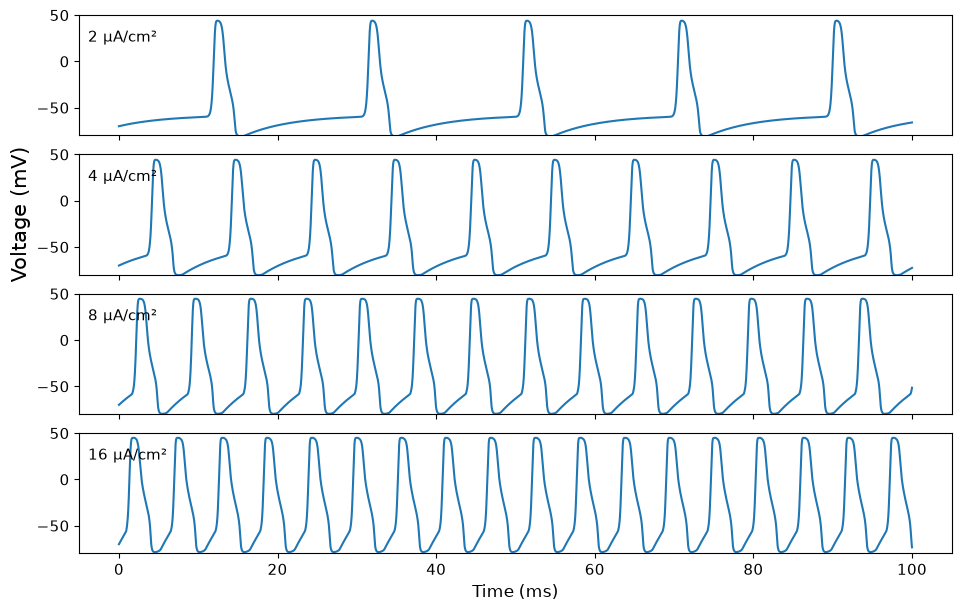

In [5]:
# ============================================================
# Figure 1: Constant-stimulus voltage traces
# ============================================================

stimuli = [2.0, 4.0, 8.0, 16.0]
traces = [simulate_single_neuron(I, AP_BASE, SIM) for I in stimuli]

fig, axs = plt.subplots(4, 1, figsize=(9.5, 6), sharex=True, constrained_layout=True)
for ax, I, out in zip(axs, stimuli, traces):
    ax.plot(out["t"], out["V"], lw=1.5)
    ax.set_ylim(-80, 50)
    ax.set_yticks([-50, 0, 50])
    ax.text(0.01, 0.78, f"{I:g} μA/cm²", transform=ax.transAxes)
    if ax is axs[1]:
        ax.set_ylabel("Voltage (mV)", fontsize=15)
axs[-1].set_xlabel("Time (ms)", fontsize=12)
fig.savefig("Figure 1.png", dpi=300, bbox_inches="tight")
fig.savefig("Figure 1.pdf", bbox_inches="tight")
plt.show()
